In [1]:
from gensim.models import Word2Vec
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


WORD2VEC TRAINING RESULT

Vocabulary:
['learning', 'is', 'machine', 'python', 'love', 'i', 'science', 'data', 'networks', 'neural', 'uses', 'deep', 'interesting', 'for', 'useful', 'learn', 'to', 'easy', 'powerful', 'are']

Total number of words: 20

Embedding vector for: learning
[-1.81232207e-03  6.28120964e-04  1.02567477e-02  1.85265094e-02
 -1.90883894e-02 -1.50452871e-02  1.38964783e-02  1.82861611e-02
 -1.08218100e-02 -8.17506108e-03  1.52630163e-02 -3.13913287e-03
 -8.73037893e-03  1.26533890e-02 -9.98649001e-03 -3.38064018e-03
  6.23405538e-03  2.44889944e-03 -1.78681035e-02 -1.98779088e-02
  1.51340803e-02  1.08815832e-02  1.50612220e-02  1.80510187e-03
  1.26078511e-02 -6.86264830e-03 -1.85633253e-03  1.20636597e-02
 -1.56565849e-02 -8.19389801e-03 -1.48687046e-02 -2.41734274e-03
  1.94988810e-02 -1.51273739e-02 -4.87281242e-03 -4.09389893e-03
  1.71646308e-02 -1.21177649e-02 -3.82214748e-05 -9.15261917e-03
 -1.89090054e-02  1.02939885e-02 -1.80398505e-02 -9.14322771e-03
  1.

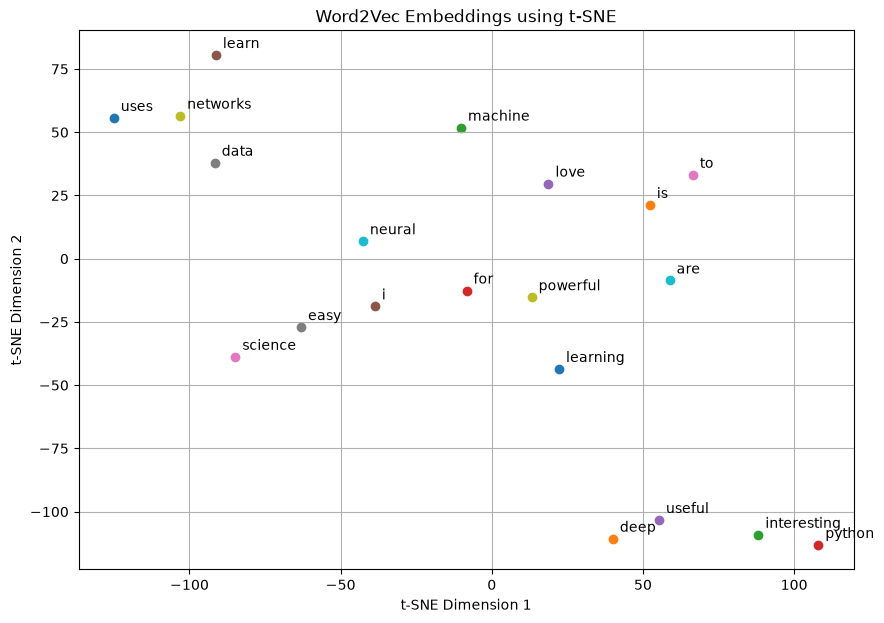

In [4]:
from gensim.models import Word2Vec
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------
# 1. Small text corpus
# -----------------------------
sentences = [
    ["i", "love", "machine", "learning"],
    ["machine", "learning", "is", "interesting"],
    ["i", "love", "deep", "learning"],
    ["deep", "learning", "uses", "neural", "networks"],
    ["neural", "networks", "are", "powerful"],
    ["i", "love", "python"],
    ["python", "is", "easy", "to", "learn"],
    ["python", "is", "useful", "for", "machine", "learning"],
    ["data", "science", "uses", "machine", "learning"],
    ["data", "science", "is", "interesting"]
]

# -----------------------------
# 2. Train Word2Vec
# -----------------------------
model = Word2Vec(
    sentences,
    vector_size=50,
    window=3,
    min_count=1,
    workers=1,
    epochs=100
)

# -----------------------------
# 3. Get vocabulary
# -----------------------------
words = list(model.wv.index_to_key)

print("=" * 50)
print("WORD2VEC TRAINING RESULT")
print("=" * 50)

print("\nVocabulary:")
print(words)

print("\nTotal number of words:", len(words))

# -----------------------------
# 4. Display vector of a word
# -----------------------------
word = "learning"

print("\nEmbedding vector for:", word)
print(model.wv[word])

print("\nVector dimension:")
print(model.wv[word].shape)

# -----------------------------
# 5. Find similar words
# -----------------------------
print("\nWords similar to 'learning':")

similar_words = model.wv.most_similar("learning", topn=5)

for w, score in similar_words:
    print(w, "->", round(score, 4))

# -----------------------------
# 6. Convert vectors to NumPy
# -----------------------------
vectors = np.array([
    model.wv[word]
    for word in words
])

print("\nAll embedding vectors shape:")
print(vectors.shape)

# -----------------------------
# 7. Apply t-SNE
# -----------------------------
tsne = TSNE(
    n_components=2,
    perplexity=3,
    random_state=42
)

vectors_2d = tsne.fit_transform(vectors)

print("\n" + "=" * 50)
print("t-SNE RESULT")
print("=" * 50)

print("\n2D coordinates:")

for i, word in enumerate(words):
    print(
        word,
        "-> X:",
        round(vectors_2d[i][0], 4),
        "Y:",
        round(vectors_2d[i][1], 4)
    )

# -----------------------------
# 8. Plot
# -----------------------------
plt.figure(figsize=(10, 7))

for i, word in enumerate(words):

    x = vectors_2d[i, 0]
    y = vectors_2d[i, 1]

    plt.scatter(x, y)

    plt.annotate(
        word,
        (x, y),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("Word2Vec Embeddings using t-SNE")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.grid()

plt.show()